# **Step 4 – Reducción y proyección de datos**
**Proyecto TA – Análisis de Datos (1INF03, 2026-2) – Equipo E10**

> *KDD, paso 4:* «Data reduction and projection: finding useful features to represent the data. Using methods to reduce the number of variables.»

Entrada: `datos/2_limpios/step3_evaluaciones.csv` (una fila = un NNA en un mes de 2026, con peso, talla, IMC, edad, sexo y la etiqueta de la ficha del mismo mes).
Salidas: `datos/3_transformados/step4_train.csv`, `step4_test.csv` (**sin escalar**) y `step4_particion.json`.

**Qué se decide aquí**
1. **Partición entrenamiento/prueba por niño:** un niño tiene varias evaluaciones parecidas; si se repartieran entre ambos conjuntos, el modelo "reconocería al niño" y la evaluación sería optimista.
2. **Variables ajustadas por edad:** el estado nutricional depende de cuánto se **desvía** una medida de lo esperado para la edad y el sexo. Se calculan residuos respecto a la edad.
3. **Escalado:** necesario para KNN y SVC (distancias) y útil para la regresión logística.
4. **Reducción de dimensiones:** se evalúa PCA.

Todo se ajusta **solo con entrenamiento**. Los residuos y el escalado se definen aquí y el Step 6 los vuelve a ajustar **dentro de cada pliegue** de la validación cruzada (`Pipeline`); por eso se guardan los datos sin transformar.

## Librerías y rutas

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
LIM, OUT = Path("../datos/2_limpios"), Path("../datos/3_transformados")
RES, FIG = Path("../datos/4_resultados"), Path("../figuras")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
SEED = 2026
ev = pd.read_csv(LIM/"step3_evaluaciones.csv", sep="|")
VARS = ["edad_ev","sexo_m","Peso_kg","Talla_cm","IMC_valor"]
print("Evaluaciones:", ev.shape, "| niños:", ev["id_nna"].nunique())
ev[VARS].describe().round(2)

Evaluaciones: (324, 18) | niños: 121


,edad_ev,sexo_m,Peso_kg,Talla_cm,IMC_valor
count,324.00,324.00,324.00,324.00,324.00
mean,9.43,0.57,34.22,128.20,19.43
std,4.11,0.50,16.96,22.57,3.68
min,1.03,0.00,7.65,72.20,13.61
25%,6.45,0.00,21.30,113.48,16.72
50%,9.26,1.00,29.28,127.75,18.66
75%,12.28,1.00,46.04,146.35,21.36
max,17.96,1.00,95.45,170.90,35.34


## 1. Relación entre las variables
Antes de transformar se mide la correlación entre predictores y se grafica el peso según la edad, coloreado por la etiqueta estricta.

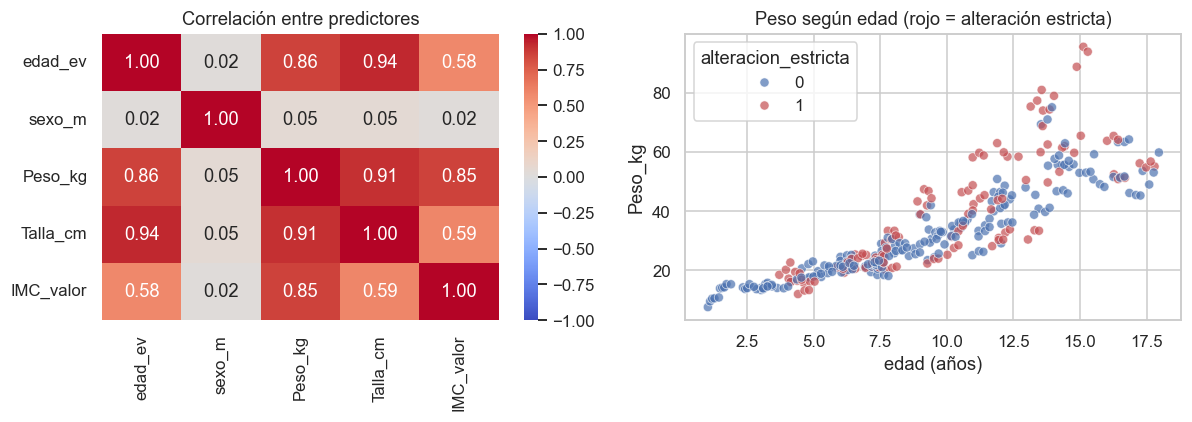

           edad_ev  sexo_m  Peso_kg  Talla_cm  IMC_valor
edad_ev       1.00    0.02     0.86      0.94       0.58
sexo_m        0.02    1.00     0.05      0.05       0.02
Peso_kg       0.86    0.05     1.00      0.91       0.85
Talla_cm      0.94    0.05     0.91      1.00       0.59
IMC_valor     0.58    0.02     0.85      0.59       1.00


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11,4))
corr = ev[VARS].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title("Correlación entre predictores")
sns.scatterplot(data=ev, x="edad_ev", y="Peso_kg", hue="alteracion_estricta", palette=["#4C72B0","#C44E52"], alpha=.7, ax=ax[1])
ax[1].set_title("Peso según edad (rojo = alteración estricta)"); ax[1].set_xlabel("edad (años)")
plt.tight_layout(); plt.savefig(FIG/"step4_correlaciones_medidas.png", bbox_inches="tight"); plt.show()
print(corr.round(2).to_string())

**Interpretación.** Edad, peso y talla están **muy correlacionados** entre sí (r entre 0,86 y 0,94) y el IMC se deriva de peso y talla (r = 0,85 con el peso); el sexo casi no se relaciona con las medidas (|r| ≤ 0,05). En el gráfico, los niños con alteración estricta (rojo) aparecen **a todas las edades**, sobre todo por encima de la nube de pesos típicos de su edad (exceso de peso), pero también mezclados con los demás. Ni la edad ni el peso por sí solos separan las clases: lo informativo es **cuánto se aleja un niño de lo esperado para su edad** (§3). La colinealidad desestabiliza los coeficientes de la regresión logística, por lo que se usará regularización.

## 2. Partición entrenamiento / prueba **por niño**
Se separan **niños**, no filas: todas las evaluaciones de un niño van al mismo conjunto. Se estratifica por la etiqueta estricta del niño (1 si alguna de sus evaluaciones la tiene), 75 % / 25 %, semilla 2026.

In [3]:
nino = ev.groupby("id_nna")["alteracion_estricta"].max()
ninos_tr, ninos_te = train_test_split(nino.index, test_size=0.25, stratify=nino, random_state=SEED)
tr = ev[ev["id_nna"].isin(ninos_tr)].reset_index(drop=True); te = ev[ev["id_nna"].isin(ninos_te)].reset_index(drop=True)
solap = len(set(ninos_tr) & set(ninos_te))
print("Niños: train", len(ninos_tr), "| test", len(ninos_te), "| solapamiento:", solap)
print("Filas: train", len(tr), "| test", len(te))
for t in ["alteracion_estricta","alteracion"]:
    print(f"% positivos {t}: total {100*ev[t].mean():.1f} | train {100*tr[t].mean():.1f} | test {100*te[t].mean():.1f}")

Niños: train 90 | test 31 | solapamiento: 0
Filas: train 236 | test 88
% positivos alteracion_estricta: total 37.3 | train 37.3 | test 37.5
% positivos alteracion: total 66.7 | train 67.4 | test 64.8


**Interpretación.** Ningún niño está en ambos conjuntos (solapamiento 0) y la prevalencia de la etiqueta estricta es prácticamente igual (37,3 % en entrenamiento y 37,5 % en prueba). El conjunto de prueba (31 niños, 88 evaluaciones) **no se vuelve a usar** hasta la evaluación final. Con tan pocos niños sus métricas tendrán mucha incertidumbre; por eso la comparación de modelos se hace con **validación cruzada agrupada por niño** dentro de entrenamiento y con varias semillas de partición (Step 6).

## 3. Variables ajustadas por edad (residuos)
`ResiduosEdad` ajusta, **por sexo y solo con los datos que recibe en `fit`**, un polinomio de grado 3 de la edad para peso, talla e IMC. El **residuo** (valor observado − esperado para su edad y sexo) indica cuánto se aleja el niño de lo típico. Es una versión simple y propia del equipo de lo que hacen las curvas OMS, calculada con los datos del Puericultorio. Al ser un transformador de scikit-learn, se puede poner dentro de un `Pipeline` (Step 6).

In [4]:
class ResiduosEdad(BaseEstimator, TransformerMixin):
    """Agrega res_peso, res_talla, res_imc = valor - esperado(edad, sexo), con un polinomio de grado 3 por sexo."""
    MED = {"Peso_kg": "res_peso", "Talla_cm": "res_talla", "IMC_valor": "res_imc"}
    def fit(self, X, y=None):
        self.curvas_ = {(c, s): LinearRegression().fit(self._f(X[X["sexo_m"] == s]), X.loc[X["sexo_m"] == s, c])
                        for c in self.MED for s in (0, 1)}
        return self
    def transform(self, X):
        X = X.copy()
        for c, nom in self.MED.items():
            X[nom] = np.nan
            for s in (0, 1):
                m = X["sexo_m"] == s
                if m.any(): X.loc[m, nom] = X.loc[m, c] - self.curvas_[(c, s)].predict(self._f(X[m]))
        return X
    @staticmethod
    def _f(d): e = d["edad_ev"].to_numpy(); return np.c_[e, e**2, e**3]

res_edad = ResiduosEdad().fit(tr[VARS])
R_tr, R_te = res_edad.transform(tr[VARS]), res_edad.transform(te[VARS])
RES_COLS = list(ResiduosEdad.MED.values())
print("Media de los residuos en train (≈0 por construcción):", R_tr[RES_COLS].mean().round(3).to_dict())

Media de los residuos en train (≈0 por construcción): {'res_peso': -0.0, 'res_talla': 0.0, 'res_imc': -0.0}


Se grafican las curvas ajustadas sobre los datos de entrenamiento.

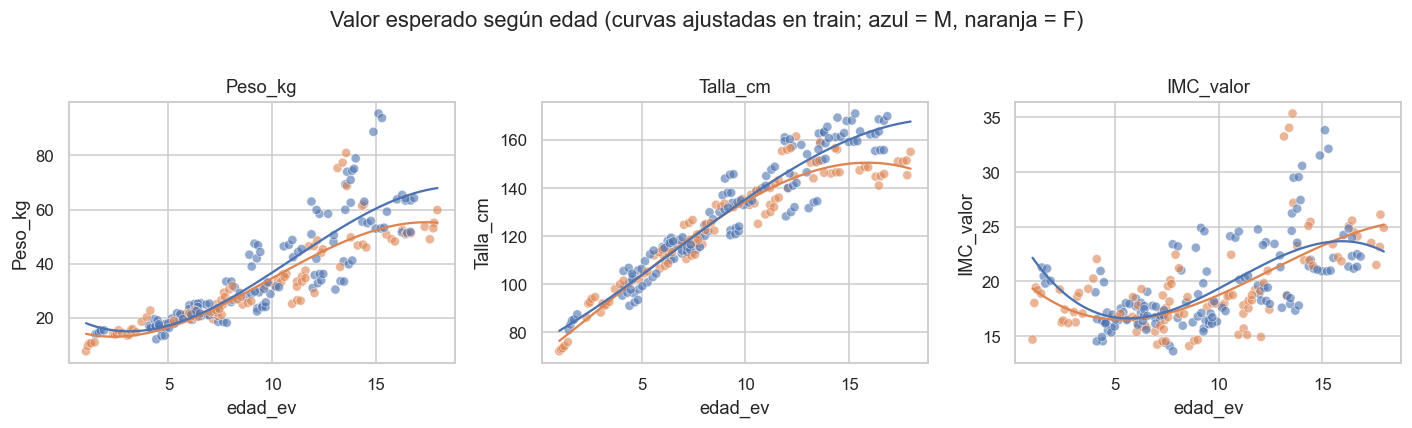

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13,3.8))
xs = pd.DataFrame({"edad_ev": np.linspace(tr["edad_ev"].min(), tr["edad_ev"].max(), 100)})
for a, c in zip(ax, ResiduosEdad.MED):
    sns.scatterplot(data=tr, x="edad_ev", y=c, hue="sexo_m", palette=["#DD8452","#4C72B0"], alpha=.6, ax=a, legend=False)
    for s, col in [(0,"#DD8452"),(1,"#4C72B0")]: a.plot(xs["edad_ev"], res_edad.curvas_[(c, s)].predict(ResiduosEdad._f(xs)), color=col)
    a.set_title(c)
plt.suptitle("Valor esperado según edad (curvas ajustadas en train; azul = M, naranja = F)", y=1.02)
plt.tight_layout(); plt.savefig(FIG/"step4_curvas_edad.png", bbox_inches="tight"); plt.show()

Se compara el residuo medio de los niños con y sin alteración estricta (solo train).

                     res_peso  res_talla  res_imc
alteracion_estricta                              
0                       -2.21       0.47    -1.13
1                        3.72      -0.79     1.90


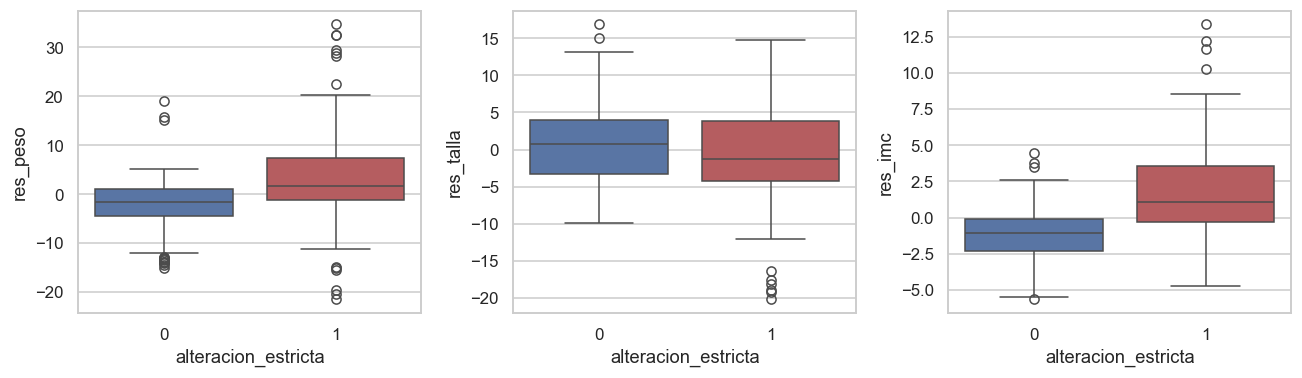

Correlación entre residuos (train):
           res_peso  res_talla  res_imc
res_peso       1.00       0.67     0.89
res_talla      0.67       1.00     0.33
res_imc        0.89       0.33     1.00


In [6]:
aux = tr[["alteracion_estricta"]].join(R_tr[RES_COLS])
res_medio = aux.groupby("alteracion_estricta").mean().round(2); print(res_medio.to_string())
fig, ax = plt.subplots(1, 3, figsize=(12,3.6))
for a, c in zip(ax, RES_COLS): sns.boxplot(data=aux, x="alteracion_estricta", y=c, ax=a, palette=["#4C72B0","#C44E52"])
plt.tight_layout(); plt.savefig(FIG/"step4_residuos_por_etiqueta.png", bbox_inches="tight"); plt.show()
print("Correlación entre residuos (train):"); print(R_tr[RES_COLS].corr().round(2).to_string())

**Interpretación.** Una vez descontado el efecto de la edad, los niños con alteración estricta tienen **residuos distintos**: en promedio +3,7 kg de peso, −0,8 cm de talla y +1,9 puntos de IMC respecto a lo esperado para su edad y sexo, frente a −2,2 kg, +0,5 cm y −1,1 puntos de los niños sin alteración. Es coherente con la definición de la etiqueta (exceso de peso **o** retraso de talla) y respalda usar las variables ajustadas junto a las crudas. Las cajas se solapan y hay valores extremos, por lo que se espera una señal **moderada**. Los residuos de peso e IMC siguen muy relacionados (r = 0,89); por eso en el Step 6 se compara con y sin ellos.

## 4. Escalado
`StandardScaler` (media 0, desvío 1) ajustado con entrenamiento y aplicado a prueba, sobre edad, peso, talla, IMC y los tres residuos; `sexo_m` queda como 0/1. Aquí se muestra como evidencia; en el Step 6 va dentro del `Pipeline`.

In [7]:
CONT = ["edad_ev","Peso_kg","Talla_cm","IMC_valor"] + RES_COLS
sc = StandardScaler().fit(R_tr[CONT])
Z_tr = pd.DataFrame(sc.transform(R_tr[CONT]), columns=CONT); Z_te = pd.DataFrame(sc.transform(R_te[CONT]), columns=CONT)
esc = pd.concat({"train": Z_tr.agg(["mean","std"]).T, "test": Z_te.agg(["mean","std"]).T}, axis=1).round(2); esc

train       test      
           mean  std  mean   std
edad_ev     0.0  1.0  0.09  0.87
Peso_kg    -0.0  1.0 -0.00  0.77
Talla_cm   -0.0  1.0  0.07  0.85
IMC_valor   0.0  1.0 -0.01  0.70
res_peso    0.0  1.0 -0.09  0.78
res_talla   0.0  1.0 -0.13  1.12
res_imc    -0.0  1.0  0.03  0.81

**Interpretación.** En entrenamiento las variables quedan con media 0 y desvío 1 por construcción; en prueba **no** (p. ej. IMC con desvío 0,70), y es lo correcto: se aplican los parámetros del entrenamiento, como se haría con datos nuevos. Escalar con todos los datos antes de partir filtraría información del conjunto de prueba.

## 5. ¿Reducir dimensiones con PCA?
Se evalúa cuántos componentes se necesitan para explicar la varianza de las 4 medidas continuas (solo train, escaladas).

Varianza explicada: [0.841 0.137 0.019 0.002] | acumulada: [0.841 0.979 0.998 1.   ]
        CP1   CP2
edad   0.50 -0.43
peso   0.54  0.15
talla  0.51 -0.41
IMC    0.44  0.79


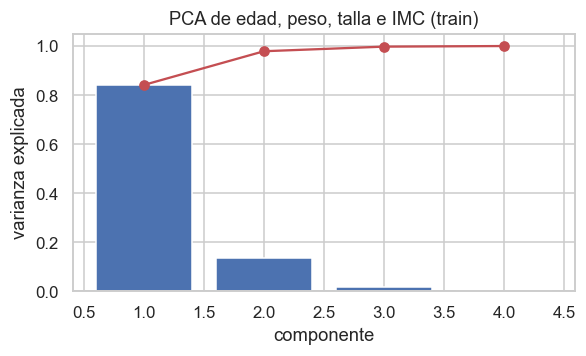

In [8]:
pca = PCA().fit(Z_tr[["edad_ev","Peso_kg","Talla_cm","IMC_valor"]])
var = pca.explained_variance_ratio_
print("Varianza explicada:", var.round(3), "| acumulada:", var.cumsum().round(3))
cargas = pd.DataFrame(pca.components_[:2].T, index=["edad","peso","talla","IMC"], columns=["CP1","CP2"]).round(2); print(cargas.to_string())
fig, ax = plt.subplots(figsize=(5.5,3.4)); ax.bar(range(1,5), var); ax.plot(range(1,5), var.cumsum(), "o-", color="#C44E52")
ax.set_xlabel("componente"); ax.set_ylabel("varianza explicada"); ax.set_title("PCA de edad, peso, talla e IMC (train)"); plt.tight_layout()
plt.savefig(FIG/"step4_pca_medidas.png", bbox_inches="tight"); plt.show()

**Interpretación y decisión.** El primer componente explica el **84,1 %** de la varianza con cargas parecidas en edad, peso y talla (0,50 a 0,54): es **tamaño corporal**, es decir, el PCA recupera que los niños mayores son más grandes, no el estado nutricional. El segundo (13,7 %) contrapone el IMC a la edad y la talla. Con solo 4 medidas el PCA no simplifica casi nada y **haría perder interpretabilidad**, importante para que la nutricionista entienda el modelo. **Decisión: no se usa PCA.** La reducción se decide comparando con validación tres conjuntos de variables: crudas, crudas + ajustadas y solo ajustadas (Step 6).

## 6. Guardado
Se guardan train y test **sin escalar** (el Step 6 ajusta residuos y escalado dentro de cada pliegue) y la lista de niños de cada conjunto.

In [9]:
COLS = ["id_nna","periodo","edad_ev","sexo_m","Peso_kg","Talla_cm","IMC_valor","alteracion_estricta","alteracion"]
tr[COLS].to_csv(OUT/"step4_train.csv", index=False, sep="|", encoding="utf-8")
te[COLS].to_csv(OUT/"step4_test.csv", index=False, sep="|", encoding="utf-8")
json.dump({"semilla": SEED, "ninos_train": sorted(ninos_tr), "ninos_test": sorted(ninos_te)}, open(OUT/"step4_particion.json", "w"), indent=1)
print("Guardado:", tr[COLS].shape, te[COLS].shape)

Guardado: (236, 9) (88, 9)


## 7. Reporte de reducción y proyección

| # | Paso | Resultado | Justificación |
|---|---|---|---|
| 1 | Unidad de análisis: niño × mes | 324 evaluaciones, 121 niños | La etiqueta se toma del mismo mes que la medición |
| 2 | Partición **por niño** 75/25, estratificada, semilla 2026 | 90 niños (236 evaluaciones) en train y 31 (88) en test, sin solapamiento | Evita que evaluaciones de un mismo niño estén en ambos conjuntos |
| 3 | Residuos respecto a la edad (por sexo, grado 3) | 3 variables nuevas (`ResiduosEdad`) | El estado nutricional es una desviación respecto a lo esperado para la edad |
| 4 | `StandardScaler` ajustado en train | 7 continuas escaladas + `sexo_m` | KNN y SVC usan distancias; evita fuga desde prueba |
| 5 | PCA evaluado y **descartado** | CP1 = 84,1 % (tamaño corporal) | No simplifica con 4 medidas y pierde interpretabilidad |
| 6 | Datos guardados sin transformar | `step4_train.csv`, `step4_test.csv` | Residuos y escalado se reajustan en cada pliegue (Step 6) |

## Verificación y cifras de este notebook

In [10]:
assert (len(ninos_tr), len(ninos_te), solap, len(tr), len(te)) == (90, 31, 0, 236, 88)
assert round(100*tr["alteracion_estricta"].mean(), 1) == 37.3 and round(100*te["alteracion_estricta"].mean(), 1) == 37.5
assert round(var[0], 3) == 0.841 and res_medio.loc[1, "res_peso"] == 3.72
cifras = {"ninos_train": len(ninos_tr), "ninos_test": len(ninos_te), "filas_train": len(tr), "filas_test": len(te),
          "pca_cp1": round(float(var[0])*100, 1), "res_peso_con_alteracion": float(res_medio.loc[1, "res_peso"])}
json.dump(cifras, open(RES/"cifras_step4.json", "w"), indent=1); cifras

{'ninos_train': 90,
 'ninos_test': 31,
 'filas_train': 236,
 'filas_test': 88,
 'pca_cp1': 84.1,
 'res_peso_con_alteracion': 3.72}

## Declaración de uso de IA
Se usó **Claude Code (Anthropic)** para convertir el cálculo de residuos por edad en un transformador de scikit-learn (`ResiduosEdad`), de modo que el Step 6 lo ajuste dentro de cada pliegue y no haya fuga de información. El equipo verificó con los `assert` que las cifras citadas coinciden con las salidas.

Siguiente: `Step5_Seleccion_Tarea_de_Mineria.ipynb`.